# Liberaries

In [ ]:
import os
import glob
import torch
import kagglehub
import numpy as np
import matplotlib.pyplot as plt
import torchvision.transforms as transforms
from torch import nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.utils as vutils

# Dataset

In [ ]:
dataset_path = kagglehub.dataset_download("kokeyehya/cmp-facade-db-base")
im_size = 256
b_size = 64

print("Path to dataset files:", dataset_path)

100%|██████████| 34.9M/34.9M [00:00<00:00, 77.3MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/kokeyehya/cmp-facade-db-base/versions/1


In [ ]:
class FacadeDataset(Dataset):
    def __init__(self, root, transforms_=None, mode='train'):
        self.transform = transforms.Compose(transforms_)
        self.images_path = sorted(glob.glob(root + '/base/*.jpg'))

        if mode == 'train':
            self.images_path = self.images_path[:int(len(self.images_path) * 0.95)]
        elif mode == 'val':
            self.images_path = self.images_path[int(len(self.images_path) * 0.95):]
        else:
            raise Exception('Invalid mode! It must be either train or val')

        self.masks_path = [image.split(".jpg")[0] + ".png" for image in self.images_path]
        assert len(self.images_path) == len(self.masks_path), "Number of images and masks must be the same"


    def __getitem__(self, index):
        img = Image.open(self.images_path[index])
        mask = Image.open(self.masks_path[index])
        mask = mask.convert('RGB')

        img = self.transform(img)
        mask = self.transform(mask)

        return img, mask

    def __len__(self):
        return len(self.images_path)

# Configure dataloaders
transforms_ = [transforms.Resize((im_size, im_size), Image.BICUBIC),
               transforms.ToTensor()]

dataloader = DataLoader(FacadeDataset(dataset_path, transforms_=transforms_),
                        batch_size=b_size, shuffle=True, drop_last=True, num_workers=4)

val_dataloader = DataLoader(FacadeDataset(dataset_path, transforms_=transforms_, mode='val'),
                            batch_size=b_size, shuffle=False)

/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


In [ ]:
def plot2x2Array(image, mask):
    f, axarr = plt.subplots(1, 2)
    axarr[0].imshow(image)
    axarr[1].imshow(mask)

    axarr[0].set_title('Image')
    axarr[1].set_title('Mask')


def reverse_transform(image):
    image = image.numpy().transpose((1, 2, 0))
    image = np.clip(image, 0, 1)
    image = (image * 255).astype(np.uint8)

    return image

def plot2x3Array(image, mask,predict):
    f, axarr = plt.subplots(1,3,figsize=(15,15))
    axarr[0].imshow(image)
    axarr[1].imshow(mask)
    axarr[2].imshow(predict)
    axarr[0].set_title('input')
    axarr[1].set_title('real')
    axarr[2].set_title('fake')

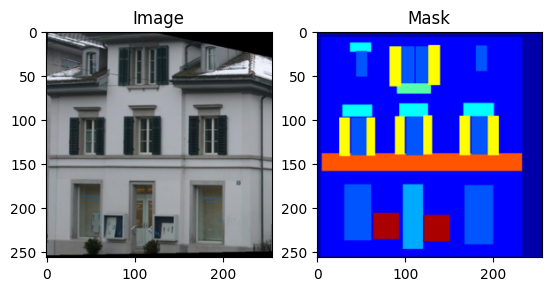

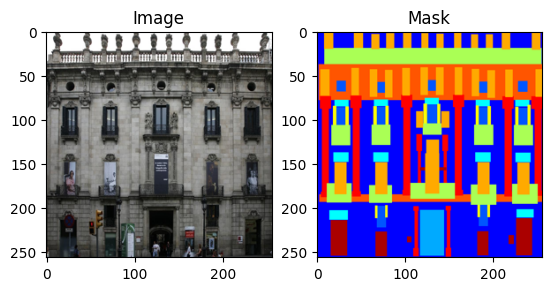

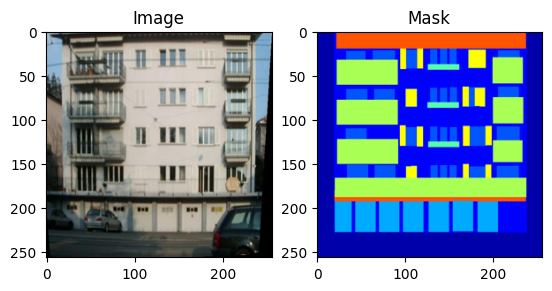

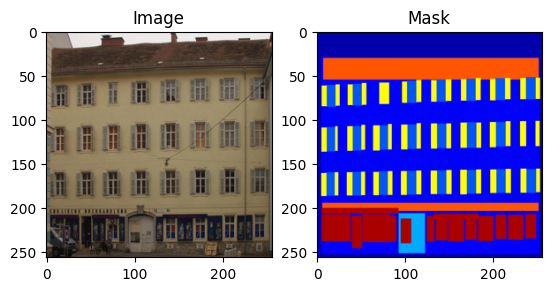

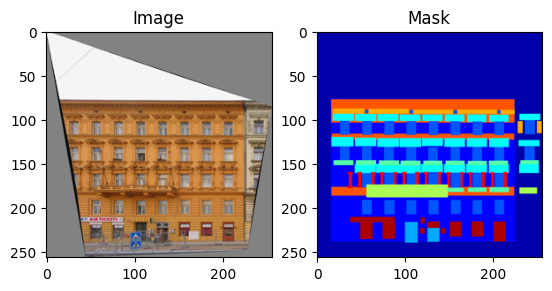

In [ ]:
images, masks = next(iter(dataloader))

for i in range(5):
    image = reverse_transform(images[i])
    mask = reverse_transform(masks[i])
    plot2x2Array(image, mask)

# Training Helpers

In [ ]:
def save_model(epoch, loss_D, loss_G):
    # save your model weights
    torch.save({
                'epoch': epoch,
                'model_state_dict': generator.state_dict(),
                'optimizer_state_dict': optimizer_G.state_dict(),
                'loss': loss_G,
                }, 'generator_'+str(epoch)+'.pth')
    torch.save({
                'epoch': epoch,
                'model_state_dict': discriminator.state_dict(),
                'optimizer_state_dict': optimizer_D.state_dict(),
                'loss': loss_D,
                }, 'discriminator_'+str(epoch)+'.pth')

def weights_init_normal(m):
  classname = m.__class__.__name__
  if classname.find('Conv') != -1:
      torch.nn.init.normal_(m.weight.data, 0.0, 0.02)
  elif classname.find('BatchNorm2d') != -1:
      torch.nn.init.normal_(m.weight.data, 1.0, 0.02)
      torch.nn.init.constant_(m.bias.data, 0.0)

def load_model(epoch=200):
    if 'generator_'+str(epoch)+'.pth' in os.listdir() and 'discriminator_'+str(epoch)+'.pth' in os.listdir():
        checkpoint_generator = torch.load('generator_'+str(epoch)+'.pth', map_location=device)
        generator.load_state_dict(checkpoint_generator['model_state_dict'])
        optimizer_G.load_state_dict(checkpoint_generator['optimizer_state_dict'])
        epoch_G = checkpoint_generator['epoch']
        loss_G = checkpoint_generator['loss']

        checkpoint_discriminator = torch.load('discriminator_'+str(epoch)+'.pth', map_location=device)
        discriminator.load_state_dict(checkpoint_discriminator['model_state_dict'])
        optimizer_D.load_state_dict(checkpoint_discriminator['optimizer_state_dict'])
        epoch_D = checkpoint_discriminator['epoch']
        loss_D = checkpoint_discriminator['loss']

    else:
        print('There isn\' a training available with this number of epochs')


def live_plot_gan(data_dict, figsize=(18, 5), title="GAN Training Progress"):
    from IPython.display import clear_output
    import matplotlib.pyplot as plt

    clear_output(wait=True)
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=figsize)

    ax1.set_title("Losses")
    ax1.set_xlabel("Epochs")
    ax1.grid(True)
    lines = []
    labels = []

    if "D Loss" in data_dict:
        l_d, = ax1.plot(data_dict["D Loss"], "r-", label="Discriminator Loss", marker='o')
        ax1.set_ylabel("Discriminator Loss", color=l_d.get_color())
        ax1.tick_params(axis='y', labelcolor=l_d.get_color())
        lines.append(l_d)
        labels.append("Discriminator Loss")

    if "G Loss" in data_dict:
        if "D Loss" in data_dict:
            ax1_right = ax1.twinx()
            l_g, = ax1_right.plot(data_dict["G Loss"], "b-", label="Generator Loss", marker='o')
            ax1_right.set_ylabel("Generator Loss", color=l_g.get_color())
            ax1_right.tick_params(axis='y', labelcolor=l_g.get_color())
            lines.append(l_g)
            labels.append("Generator Loss")
        else:
            l_g, = ax1.plot(data_dict["G Loss"], "b-", label="Generator Loss", marker='o')
            ax1.set_ylabel("Generator Loss", color=l_g.get_color())
            ax1.tick_params(axis='y', labelcolor=l_g.get_color())
            lines.append(l_g)
            labels.append("Generator Loss")

    ax1.legend(lines, labels, loc='upper right')

    ax2.set_title("Discriminator Output")
    ax2.set_xlabel("Epochs")
    ax2.grid(True)
    lines = []
    labels = []

    if "D(x)" in data_dict:
        l_dx, = ax2.plot(data_dict["D(x)"], "r--", label="D(x)", marker='x', alpha=0.7)
        ax2.set_ylabel("D(x)", color=l_dx.get_color())
        ax2.tick_params(axis='y', labelcolor=l_dx.get_color())
        lines.append(l_dx)
        labels.append("D(x)")

    if "D(G(z))" in data_dict:
        if "D(x)" in data_dict:
            ax2_right = ax2.twinx()
            l_dgz, = ax2_right.plot(data_dict["D(G(z))"], "g-", label="D(G(z))", marker='^')
            ax2_right.set_ylabel("D(G(z))", color=l_dgz.get_color())
            ax2_right.tick_params(axis='y', labelcolor=l_dgz.get_color())
            lines.append(l_dgz)
            labels.append("D(G(z))")
        else:
            l_dgz, = ax2.plot(data_dict["D(G(z))"], "g-", label="D(G(z))", marker='^')
            ax2.set_ylabel("D(G(z))", color=l_dgz.get_color())
            ax2.tick_params(axis='y', labelcolor=l_dgz.get_color())
            lines.append(l_dgz)
            labels.append("D(G(z))")

    ax2.legend(lines, labels, loc='upper right')

    ax3.set_title("Parameter Update Ratios")
    ax3.set_xlabel("Epochs")
    ax3.grid(True)

    if "Update Gen" in data_dict:
        l1, = ax3.plot(data_dict["Update Gen"], "b-", label="Generator Update Ratio", marker='o')
        ax3.set_ylabel("Generator Update Ratio", color=l1.get_color())
        ax3.tick_params(axis='y', labelcolor=l1.get_color())

    ax3_right = ax3.twinx()
    if "Update Disc" in data_dict:
        l2, = ax3_right.plot(data_dict["Update Disc"], "r-", label="Discriminator Update Ratio", marker='^')
        ax3_right.set_ylabel("Discriminator Update Ratio", color=l2.get_color())
        ax3_right.tick_params(axis='y', labelcolor=l2.get_color())

    ax3.axhline(y=0.001, color='gray', linestyle='--', label='Target Ratio (10^-3)')

    lines, labels = ax3.get_legend_handles_labels()
    lines2, labels2 = ax3_right.get_legend_handles_labels()
    ax3.legend(lines + lines2, labels + labels2, loc='upper right')

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

def plot_generated_images(img_grid, figsize=(14,14)):
    plt.figure(figsize=figsize)
    plt.axis("off")
    plt.title(f"Generated Images")

    plt.imshow(np.transpose(img_grid, (1, 2, 0)))
    plt.show()

def compute_update_ratio(net, optimizer):
    total_update_norm = 0.0
    total_param_norm = 0.0
    # Loop over parameter groups and parameters
    for group in optimizer.param_groups:
        lr = group.get('lr', 0.001)  # default to 0.001 if not found
        for p in net.parameters():
            if p.grad is not None:
                param_norm = p.data.norm(2)
                # Compute update magnitude using the learning rate times the gradient
                update = lr * p.grad.data
                update_norm = update.norm(2)
                total_update_norm += update_norm.item()
                total_param_norm += param_norm.item()
    # Return ratio if possible
    return total_update_norm / total_param_norm if total_param_norm > 0 else 0.0

# Helpers for the model

In [ ]:
# Input layer
class inconv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super(inconv, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=4, padding=1, stride=2),
            nn.LeakyReLU(negative_slope=0.2, inplace=True)
        )

    def forward(self, x):
        x = self.conv(x)
        return x

# Encoder layer
class down(nn.Module):
    def __init__(self, in_ch, out_ch):
        super(down, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=4, padding=1, stride=2),
            nn.BatchNorm2d(out_ch),
            nn.LeakyReLU(negative_slope=0.2, inplace=True)
        )

    def forward(self, x):
        x = self.conv(x)
        return x

# Decoder layer
class up(nn.Module):
    def __init__(self, in_ch, out_ch, dropout=False):
        super(up, self).__init__()
        if dropout :
            self.conv = nn.Sequential(
                nn.ConvTranspose2d(in_ch, out_ch, kernel_size=4, padding=1, stride=2),
                nn.BatchNorm2d(out_ch),
                nn.Dropout(0.5, inplace=True),
                nn.ReLU(inplace=True)
            )
        else:
            self.conv = nn.Sequential(
                nn.ConvTranspose2d(in_ch, out_ch, kernel_size=4, padding=1, stride=2),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True)
            )

    def forward(self, x1, x2):
        x1 = self.conv(x1)
        x = torch.cat([x1, x2], dim=1)
        return x

# Output layer
class outconv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super(outconv, self).__init__()
        self.conv = nn.Sequential(
              nn.ConvTranspose2d(in_ch, out_ch, kernel_size=4, padding=1, stride=2),
              nn.Tanh()
        )

    def forward(self, x):
        x = self.conv(x)
        return x

class conv_block(nn.Module):
    def __init__(self, in_ch, out_ch, use_batchnorm=True, stride=2):
        super(conv_block, self).__init__()
        if use_batchnorm:
            self.conv = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=4, padding=1, stride=stride),
                nn.BatchNorm2d(out_ch),
                nn.LeakyReLU(negative_slope=0.2, inplace=True)
            )
        else:
            self.conv = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=4, padding=1, stride=stride),
                nn.LeakyReLU(negative_slope=0.2, inplace=True)
            )

    def forward(self, x):
        x = self.conv(x)
        return x


class out_block(nn.Module):
    def __init__(self, in_ch, out_ch):
        super(out_block, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, 1, kernel_size=4, padding=1, stride=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.conv(x)
        return x

# Generator

In [ ]:
class U_Net(nn.Module):
    def __init__(self, n_channels, n_classes):
        super(U_Net, self).__init__()
        self.inc = inconv(n_channels, 64)
        self.down1 = down(64, 128)
        self.down2 = down(128, 256)
        self.down3 = down(256, 512)
        self.down4 = down(512, 512)
        self.down5 = down(512, 512)
        self.down6 = down(512, 512)
        self.down7 = down(512, 512)
        self.up7 = up(512, 512, dropout=True)
        self.up6 = up(1024, 512, dropout=True)
        self.up5 = up(1024, 512, dropout=True)
        self.up4 = up(1024, 512)
        self.up3 = up(1024, 256)
        self.up2 = up(512, 128)
        self.up1 = up(256, 64)
        self.outc = outconv(128, n_classes)

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)
        x6 = self.down5(x5)
        x7 = self.down6(x6)
        x8 = self.down7(x7)
        x = self.up7(x8, x7)
        x = self.up6(x, x6)
        x = self.up5(x, x5)
        x = self.up4(x, x4)
        x = self.up3(x, x3)
        x = self.up2(x, x2)
        x = self.up1(x, x1)
        x = self.outc(x)
        return x

# let's see the model arch
generator = U_Net(3, 3)

# print(generator)

<font color='red'>**Question**</font>                                                                  
Knowing the input and output images will have the shape 256x256 with 3 channels, what will be the dimension of the feature map "x8" ?

**Dimension of the feature map "x8":**

Starting with an input of size **(3, 256, 256)**, the architecture applies a series of convolutions that each downsample the spatial dimensions by a factor of 2. Here's the breakdown:

- **inconv:** (3, 256, 256) → (64, 128, 128)
- **down1:** (64, 128, 128) → (128, 64, 64)
- **down2:** (128, 64, 64) → (256, 32, 32)
- **down3:** (256, 32, 32) → (512, 16, 16)
- **down4:** (512, 16, 16) → (512, 8, 8)
- **down5:** (512, 8, 8) → (512, 4, 4)
- **down6:** (512, 4, 4) → (512, 2, 2)
- **down7:** (512, 2, 2) → (512, 1, 1)

Thus, the feature map **x8** has dimensions **(512, 1, 1)** (ignoring the batch dimension).

<font color='red'>**Question**</font>                                                                  
As you can see, U-net has an encoder-decoder architecture with skip connections. Explain what is the point of the skip connections.


**Purpose of the skip connections:**

Skip connections in U-Net serve several important purposes:

- **Preservation of Spatial Information:** As the encoder progressively downsamples the image, detailed spatial information is lost. Skip connections bring forward the high-resolution features from the encoder to the decoder, helping to recover fine-grained details.
  
- **Enhanced Localization:** Combining deep, abstract features with shallow, high-resolution features allows the network to produce more precise output, which is especially important in tasks like segmentation where accurate boundaries are crucial.
  
- **Improved Gradient Flow:** They provide a direct path for gradients during backpropagation, mitigating the vanishing gradient problem and facilitating the training of deep networks.

In summary, skip connections enable the U-Net to merge both semantic (deep) and detailed (shallow) information, leading to more accurate and robust predictions.

# Discriminator

<font color='red'>**Question**</font>                                                                  
Knowing input images will be 256x256 with 3 channels each, how many learnable parameters this neural network has ?


The network has **2,769,601 learnable parameters**.

Below is an explanation of how we arrive at that number:

1. **conv1 (from conv_block without BatchNorm):**  
   - **Convolution:** Takes an input with 6 channels (since two images with 3 channels each are concatenated) and outputs 64 channels using a 4×4 kernel.  
     - Weights: \(6 \times 64 \times 4 \times 4 = 6 \times 64 \times 16 = 6144\)  
     - Bias: 64  
     - **Total:** \(6144 + 64 = 6208\)

2. **conv2 (with BatchNorm):**  
   - **Convolution:** From 64 to 128 channels with a 4×4 kernel.  
     - Weights: \(64 \times 128 \times 16 = 131072\)  
     - Bias: 128  
   - **BatchNorm2d(128):**  
     - Learnable parameters: 128 (weight) + 128 (bias) = 256  
   - **Total:** \(131072 + 128 + 256 = 131456\)

3. **conv3 (with BatchNorm):**  
   - **Convolution:** From 128 to 256 channels with a 4×4 kernel.  
     - Weights: \(128 \times 256 \times 16 = 524288\)  
     - Bias: 256  
   - **BatchNorm2d(256):**  
     - Learnable parameters: 256 (weight) + 256 (bias) = 512  
   - **Total:** \(524288 + 256 + 512 = 525056\)

4. **conv4 (with BatchNorm):**  
   - **Convolution:** From 256 to 512 channels with a 4×4 kernel (stride 1).  
     - Weights: \(256 \times 512 \times 16 = 2097152\)  
     - Bias: 512  
   - **BatchNorm2d(512):**  
     - Learnable parameters: 512 (weight) + 512 (bias) = 1024  
   - **Total:** \(2097152 + 512 + 1024 = 2098688\)

5. **out block:**  
   - **Convolution:** From 512 channels to 1 channel with a 4×4 kernel.  
     - Weights: \(512 \times 1 \times 16 = 8192\)  
     - Bias: 1  
   - **Total:** \(8192 + 1 = 8193\)

**Summing up:**  
\[
6208 + 131456 + 525056 + 2098688 + 8193 = 2769601
\]

In [ ]:
class PatchGAN(nn.Module):
    def __init__(self, n_channels, n_classes):
        super(PatchGAN, self).__init__()
        self.conv1 = conv_block(n_channels * 2, 64, use_batchnorm=False, stride=2)
        self.conv2 = conv_block(64, 128, use_batchnorm=True, stride=2)
        self.conv3 = conv_block(128, 256, use_batchnorm=True, stride=2)
        self.conv4 = conv_block(256, 512, use_batchnorm=True, stride=1)
        self.out = out_block(512, n_classes)

    def forward(self, x1, x2):
        x = torch.cat([x2, x1], dim=1)
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)
        x = self.out(x)
        return x

# test with 256 * 256 * 3 input
model = PatchGAN(n_channels=3, n_classes=1)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(total_params)

# let's visualize the arch
discriminator = PatchGAN(6, 1)

# print(discriminator)

2769601


# Training and evaluating models

In [ ]:
# parameters
num_epochs = 200
batch_size = 16
lr = 2e-4
b1 = 0.5
b2 = 0.999
im_size = im_size
channels = 3
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
# Calculate output of image discriminator (PatchGAN)
patch_size = (1, im_size//2**3-2, im_size//2**3-2)

generator = U_Net(3, 3).to(device)
discriminator = PatchGAN(3, 1).to(device)

# Optimizers
optimizer_G = torch.optim.Adam(generator.parameters(), lr=lr, betas=(b1, b2))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=lr, betas=(b1, b2))

# Loss functions
criterion_GAN = torch.nn.BCELoss()
criterion_pixelwise = torch.nn.L1Loss()

# Loss weight of L1 pixel-wise loss between translated image and real image
lambda_pixel = 100

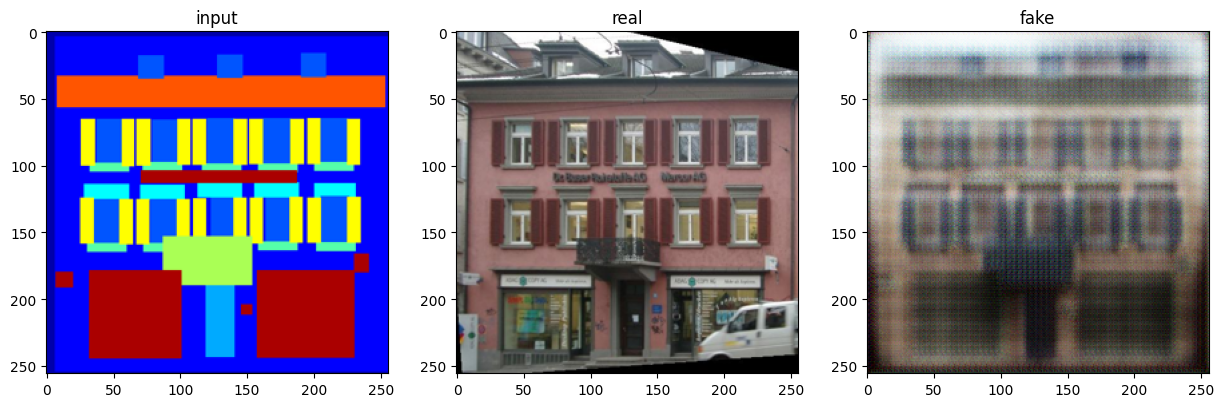

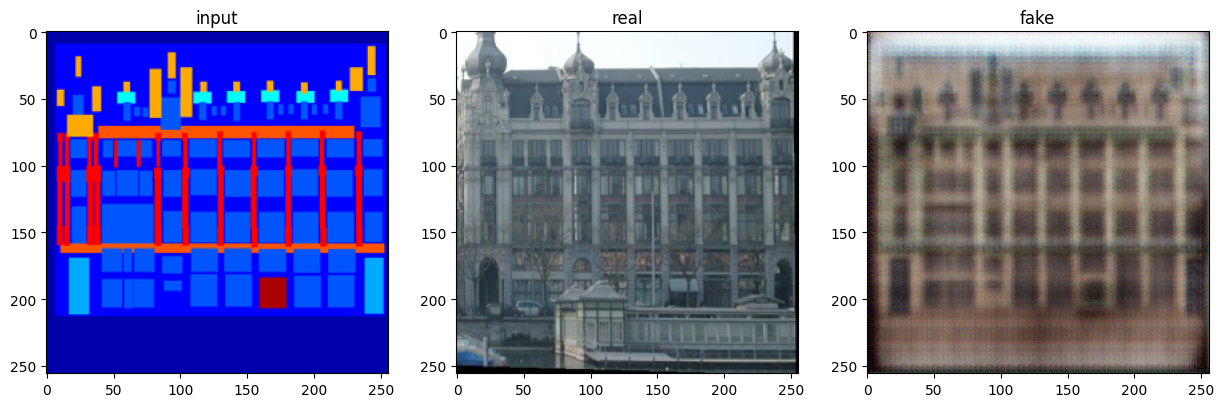

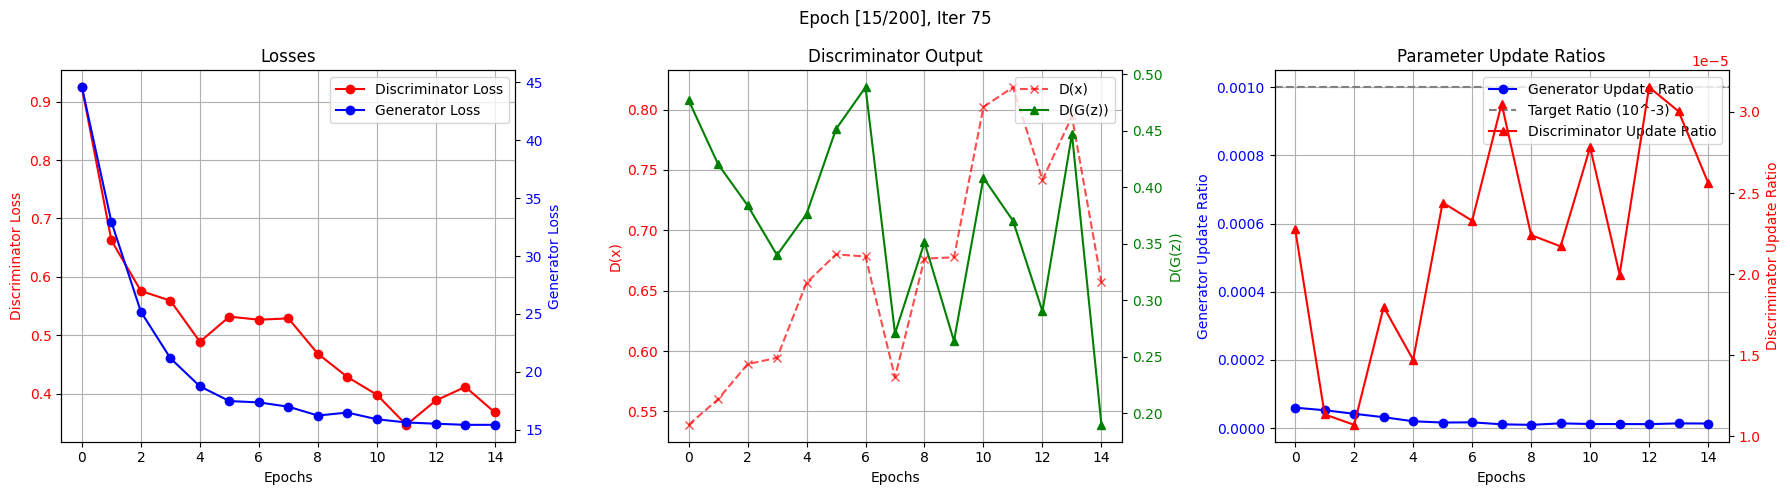

Epoch [16/200][0/5] | d_loss: 0.3259 | g_loss: 14.9802


In [ ]:
history = {
    "D Loss": [],
    "G Loss": [],
    "D(x)": [],
    "D(G(z))": [],
    "Update Gen": [],
    "Update Disc": [],
}
img_list = []
iters = 0

# Initialize weights
generator.apply(weights_init_normal)
discriminator.apply(weights_init_normal)

# Set models to training mode
discriminator.train()
generator.train()
print_every = 400

for epoch in range(num_epochs):
    d_epoch_loss = 0.0
    g_epoch_loss = 0.0
    update_gen_epoch = 0.0
    update_disc_epoch = 0.0
    num_batches = 0

    for i, batch in enumerate(dataloader):
        num_batches += 1

        # Model inputs
        images, masks = batch
        images = images.to(device)
        masks = masks.to(device)
        b_size = images.size(0)

        # Discriminator labels
        valid = torch.ones((b_size, *patch_size), requires_grad=False).to(device)
        fake = torch.zeros((b_size, *patch_size), requires_grad=False).to(device)

        # ------------------
        #  Train Generator
        # ------------------
        optimizer_G.zero_grad()

        # Generate fake images from masks
        generated_images = generator(masks)

        # GAN loss: try to fool the discriminator
        loss_GAN = criterion_GAN(discriminator(generated_images, masks), valid)

        # Pixel-wise L1 loss
        loss_pixel = criterion_pixelwise(generated_images, images)

        # Total generator loss
        loss_G = loss_GAN + lambda_pixel * loss_pixel

        loss_G.backward()
        # Compute generator update ratio (before optimizer step)
        update_gen = compute_update_ratio(generator, optimizer_G)
        optimizer_G.step()

        # ---------------------
        #  Train Discriminator
        # ---------------------
        optimizer_D.zero_grad()

        # Real loss
        pred_real = discriminator(images, masks)
        loss_real = criterion_GAN(pred_real, valid)

        # Fake loss
        pred_fake = discriminator(generated_images.detach(), masks)
        loss_fake = criterion_GAN(pred_fake, fake)

        # Total discriminator loss
        loss_D = 0.5 * (loss_real + loss_fake)

        loss_D.backward()
        # Compute discriminator update ratio (before optimizer step)
        update_disc = compute_update_ratio(discriminator, optimizer_D)
        optimizer_D.step()

        # Accumulate losses and update ratios
        d_epoch_loss += loss_D.item()
        g_epoch_loss += loss_G.item()
        update_gen_epoch += update_gen
        update_disc_epoch += update_disc

        iters += 1

    # End-of-epoch: average metrics over batches
    d_epoch_loss /= num_batches
    g_epoch_loss /= num_batches
    update_gen_epoch /= num_batches
    update_disc_epoch /= num_batches

    # Save the metrics from the last batch for D(x) and D(G(z))
    history["D Loss"].append(d_epoch_loss)
    history["G Loss"].append(g_epoch_loss)
    history["D(x)"].append(pred_real.mean().item())
    history["D(G(z))"].append(pred_fake.mean().item())
    history["Update Gen"].append(update_gen_epoch)
    history["Update Disc"].append(update_disc_epoch)

    # Save model checkpoint every 100 epochs
    if (epoch + 1) % 100 == 0:
        print('Saving model...')
        save_model(epoch+1, loss_D, loss_G)

    # --- Display pairs of images for visual tracking ---
    with torch.no_grad():
        sample_images, sample_masks = next(iter(val_dataloader))
        sample_images = sample_images.to(device)
        sample_masks = sample_masks.to(device)
        fake_samples = generator(sample_masks)
        fake_samples = fake_samples.cpu().detach()
        # Display a couple of pairs (mask, real, fake)
        for j in range(min(2, sample_images.size(0))):
            real_img = reverse_transform(sample_images[j].cpu())
            mask_img = reverse_transform(sample_masks[j].cpu())
            fake_img = reverse_transform(fake_samples[j])
            # Using the helper function: plot2x3Array(input, real, fake)
            plot2x3Array(mask_img, real_img, fake_img)

    # --- Live plot training metrics ---
    live_plot_gan({
        "D Loss": history["D Loss"],
        "G Loss": history["G Loss"],
        "D(x)": history["D(x)"],
        "D(G(z))": history["D(G(z))"],
        "Update Gen": history["Update Gen"],
        "Update Disc": history["Update Disc"]
    }, title=f"Epoch [{epoch+1}/{num_epochs}], Iter {iters}")


# Evaluate your cGAN

In [ ]:
def evaluate_checkpoint(epoch):
    # Load checkpoint
    load_model(epoch=epoch)
    generator.eval()
    with torch.no_grad():
        images, masks = next(iter(val_dataloader))
        outputs = generator(masks.to(device))
        outputs = outputs.cpu().detach()
    return images, masks, outputs

# Evaluate model at 100 and 200 epochs
images_100, masks_100, outputs_100 = evaluate_checkpoint(100)
images_200, masks_200, outputs_200 = evaluate_checkpoint(200)

# Plot and compare a few samples from both checkpoints
num_samples = 4  # Change this to display more or fewer samples
for i in range(num_samples):
    # Reverse transforms for visualization
    image_plot = reverse_transform(images_100[i])
    mask_plot = reverse_transform(masks_100[i])
    output_100_plot = reverse_transform(outputs_100[i])
    output_200_plot = reverse_transform(outputs_200[i])

    # Create a 2x3 grid: first row for epoch 100, second row for epoch 200
    f, axarr = plt.subplots(2, 3, figsize=(15,10))

    # Epoch 100 row
    axarr[0, 0].imshow(mask_plot)
    axarr[0, 0].set_title('Input (mask)')
    axarr[0, 1].imshow(image_plot)
    axarr[0, 1].set_title('Real Image')
    axarr[0, 2].imshow(output_100_plot)
    axarr[0, 2].set_title('Fake (Epoch 100)')

    # Epoch 200 row
    axarr[1, 0].imshow(mask_plot)
    axarr[1, 0].set_title('Input (mask)')
    axarr[1, 1].imshow(image_plot)
    axarr[1, 1].set_title('Real Image')
    axarr[1, 2].imshow(output_200_plot)
    axarr[1, 2].set_title('Fake (Epoch 200)')

    # Remove axis for clarity
    for ax in axarr.flatten():
        ax.axis('off')
    plt.tight_layout()
    plt.show()
